# Exploratory Data Analysis

In this notebook we explore the cleaned data: class balance, text length, vocabulary, common words for each emotion and correlations.

In [1]:
import re, json, unicodedata, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12, "axes.titleweight": "bold"})

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROC, IMG, REP = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "images", ROOT / "reports"
for p in (PROC, IMG, REP):
    p.mkdir(parents=True, exist_ok=True)

EMOTIONS = ["anger", "fear", "joy", "love", "sadness", "surprise"]
SPLITS = ["train", "val", "test"]
RANDOM_STATE = 42

NOTES = {}

def save_fig(fig, name):
    fig.savefig(IMG / f"{name}.png", dpi=200, bbox_inches="tight")

def note(name, text):
    NOTES[name] = text
    print("TAKEAWAY ->", text)

In [2]:
from scipy import stats
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.feature_selection import chi2

data = {s: pd.read_csv(PROC / f"{s}_clean.csv") for s in SPLITS}
for s, d in data.items():
    d["split"] = s
train, val, test = data["train"], data["val"], data["test"]
full = pd.concat(data.values(), ignore_index=True)

STOP = set(ENGLISH_STOP_WORDS) | {"feel", "feeling", "feels", "felt", "im", "ive", "like", "just", "really", "get", "bit"}
FACTS = {}

order = train.label.value_counts().index.tolist()
palette = dict(zip(order, sns.color_palette("tab10", len(order))))
print({s: len(d) for s, d in data.items()})
train.head()

{'train': 15923, 'val': 1993, 'test': 2000}


,text,label,is_length_outlier,split
0,i didnt feel humiliated,sadness,False,train
1,i can go from feeling so hopeless to so damned...,sadness,False,train
2,im grabbing a minute to post i feel greedy wrong,anger,False,train
3,i am ever feeling nostalgic about the fireplac...,love,False,train
4,i am feeling grouchy,anger,False,train


## 1. Overview

In [3]:
overview = pd.DataFrame({
    "rows": {s: len(d) for s, d in data.items()},
    "classes": {s: d.label.nunique() for s, d in data.items()},
    "missing_values": {s: int(d[["text", "label"]].isna().sum().sum()) for s, d in data.items()},
    "duplicate_texts": {s: int(d.text.duplicated().sum()) for s, d in data.items()},
})
FACTS["rows"] = overview["rows"].to_dict()
overview

,rows,classes,missing_values,duplicate_texts
train,15923,6,0,0
val,1993,6,0,0
test,2000,6,0,0


## 2. Class distribution

Checking if the classes are balanced. If they are not, accuracy alone is not a good metric.

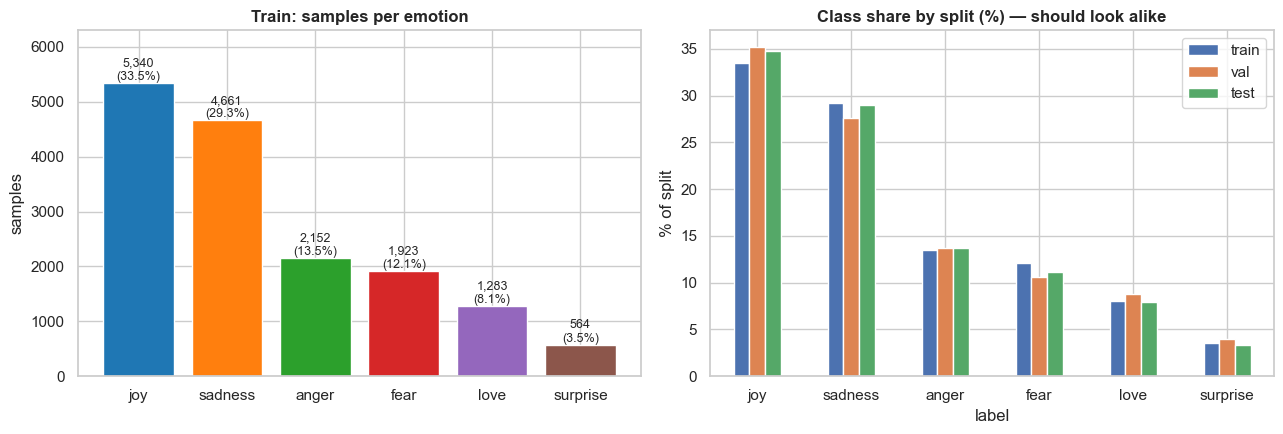

TAKEAWAY -> 'joy' is the largest class (33.5%) and 'surprise' the smallest (3.5%): imbalance ratio 9.5:1. Class mix is consistent across splits (chi-square p = 0.365).


In [4]:
counts = train.label.value_counts().reindex(order)
pct = counts / counts.sum() * 100
ratio = counts.max() / counts.min()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
bars = axes[0].bar(order, counts.values, color=[palette[c] for c in order])
for b, c, p in zip(bars, counts.values, pct.values):
    axes[0].text(b.get_x() + b.get_width() / 2, c, f"{c:,}\n({p:.1f}%)", ha="center", va="bottom", fontsize=9)
axes[0].set_ylim(0, counts.max() * 1.18); axes[0].set_title("Train: samples per emotion"); axes[0].set_ylabel("samples")

prop = pd.DataFrame({s: d.label.value_counts(normalize=True).reindex(order) * 100 for s, d in data.items()})
prop.plot.bar(ax=axes[1], rot=0); axes[1].set_title("Class share by split (%) — should look alike"); axes[1].set_ylabel("% of split")
plt.tight_layout(); save_fig(fig, "04_class_distribution"); plt.show()

ct = pd.crosstab(full.split, full.label)
chi2_p = stats.chi2_contingency(ct)[1]
FACTS.update(class_counts=counts.to_dict(), class_pct=pct.round(2).to_dict(), imbalance_ratio=float(ratio), split_chi2_p=float(chi2_p))
note("04_class_distribution", f"'{order[0]}' is the largest class ({pct.iloc[0]:.1f}%) and '{order[-1]}' the smallest ({pct.iloc[-1]:.1f}%): imbalance ratio {ratio:.1f}:1. "
     f"Class mix is {'consistent' if chi2_p > 0.05 else 'NOT consistent'} across splits (chi-square p = {chi2_p:.3f}).")

The left chart shows the number of samples per emotion and the right chart compares train, val and test. The classes are imbalanced, so I will use class weights and macro F1 in the models.

## 3. Text length

I made 5 simple features from the text: character count, word count, average word length, unique word ratio and stop word ratio.

In [5]:
def add_features(d):
    words = d.text.str.split()
    d["word_count"] = words.str.len()
    d["char_count"] = d.text.str.len()
    d["avg_word_len"] = (d.char_count - (d.word_count - 1)) / d.word_count
    d["unique_ratio"] = words.map(lambda w: len(set(w)) / len(w))
    d["stopword_ratio"] = words.map(lambda w: float(np.mean([t in STOP for t in w])))
    return d

for d in (train, val, test, full):
    add_features(d)
NUM = ["char_count", "word_count", "avg_word_len", "unique_ratio", "stopword_ratio"]
train[NUM].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
char_count,15923.0,96.92,55.95,7.00,53.00,86.00,129.00,300.00
word_count,15923.0,19.18,11.00,2.00,11.00,17.00,25.00,66.00
avg_word_len,15923.0,4.15,0.58,2.40,3.76,4.10,4.47,8.89
unique_ratio,15923.0,0.91,0.08,0.28,0.86,0.92,1.00,1.00
stopword_ratio,15923.0,0.64,0.10,0.00,0.58,0.64,0.71,1.00


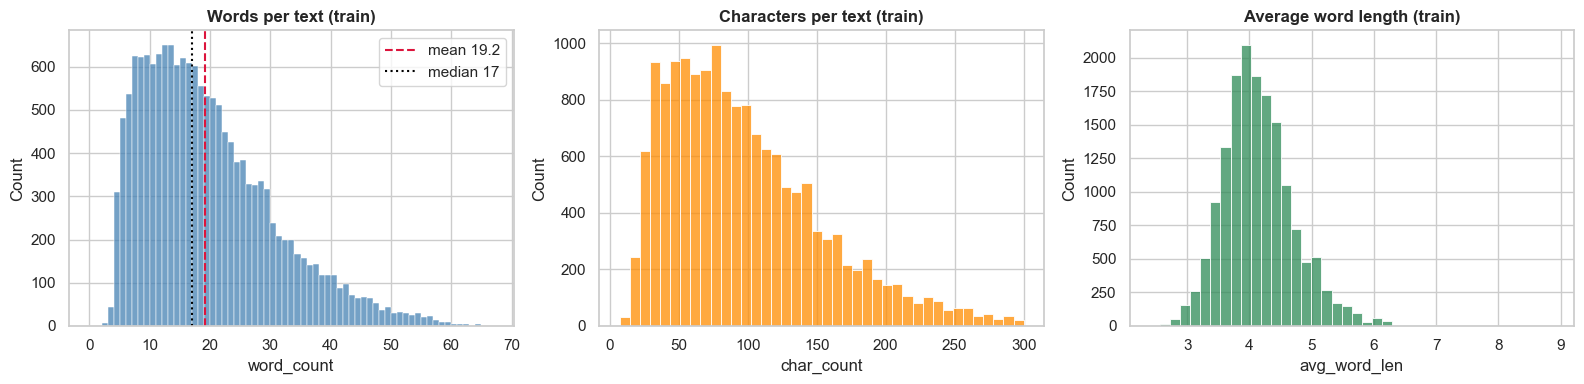

TAKEAWAY -> Texts average 19.2 words (median 17, range 2–66); skewness = 0.96 (right-skewed).


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(train.word_count, bins=range(0, int(train.word_count.max()) + 2), ax=axes[0], color="steelblue")
axes[0].axvline(train.word_count.mean(), color="crimson", ls="--", label=f"mean {train.word_count.mean():.1f}")
axes[0].axvline(train.word_count.median(), color="black", ls=":", label=f"median {train.word_count.median():.0f}")
axes[0].set_title("Words per text (train)"); axes[0].legend()
sns.histplot(train.char_count, bins=40, ax=axes[1], color="darkorange"); axes[1].set_title("Characters per text (train)")
sns.histplot(train.avg_word_len, bins=40, ax=axes[2], color="seagreen"); axes[2].set_title("Average word length (train)")
plt.tight_layout(); save_fig(fig, "05_length_histograms"); plt.show()

skew = train.word_count.skew()
FACTS.update(word_mean=float(train.word_count.mean()), word_median=float(train.word_count.median()),
             word_max=int(train.word_count.max()), word_min=int(train.word_count.min()), word_skew=float(skew))
note("05_length_histograms", f"Texts average {train.word_count.mean():.1f} words (median {train.word_count.median():.0f}, range {train.word_count.min()}–{train.word_count.max()}); "
     f"skewness = {skew:.2f} ({'right-skewed' if skew > 0.5 else 'roughly symmetric'}).")

The histograms show how long the texts are. The distribution is skewed to the right, so I will use a log transform before scaling.

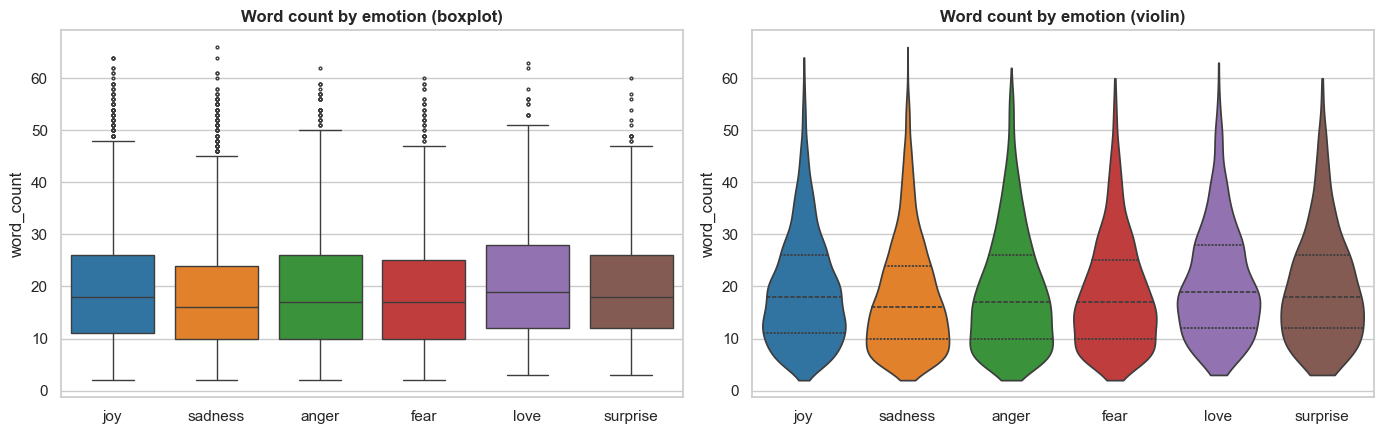

,mean,median,std
label,,,
joy,19.51,18.0,10.78
sadness,18.36,16.0,11.04
anger,19.23,17.0,11.43
fear,18.86,17.0,10.90
love,20.76,19.0,10.86
surprise,20.07,18.0,11.05


TAKEAWAY -> Longest on average: 'love' (20.8 words); shortest: 'sadness' (18.4). Kruskal-Wallis p = 3.01e-18 → length differs significantly between emotions.


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=train, x="label", y="word_count", order=order, palette=palette, ax=axes[0], flierprops={"markersize": 2})
axes[0].set_title("Word count by emotion (boxplot)"); axes[0].set_xlabel("")
sns.violinplot(data=train, x="label", y="word_count", order=order, palette=palette, ax=axes[1], cut=0, inner="quartile")
axes[1].set_title("Word count by emotion (violin)"); axes[1].set_xlabel("")
plt.tight_layout(); save_fig(fig, "06_length_by_emotion"); plt.show()

by_class = train.groupby("label").word_count.agg(["mean", "median", "std"]).reindex(order).round(2)
H, p_kw = stats.kruskal(*[g.word_count.values for _, g in train.groupby("label")])
FACTS.update(length_by_class=by_class["mean"].to_dict(), kruskal_p=float(p_kw))
display(by_class)
note("06_length_by_emotion", f"Longest on average: '{by_class['mean'].idxmax()}' ({by_class['mean'].max():.1f} words); shortest: '{by_class['mean'].idxmin()}' ({by_class['mean'].min():.1f}). "
     f"Kruskal-Wallis p = {p_kw:.3g} → length {'differs significantly between' if p_kw < 0.05 else 'does not differ between'} emotions.")

The boxplots compare the text length of each emotion. The Kruskal-Wallis test shows if the difference is significant.

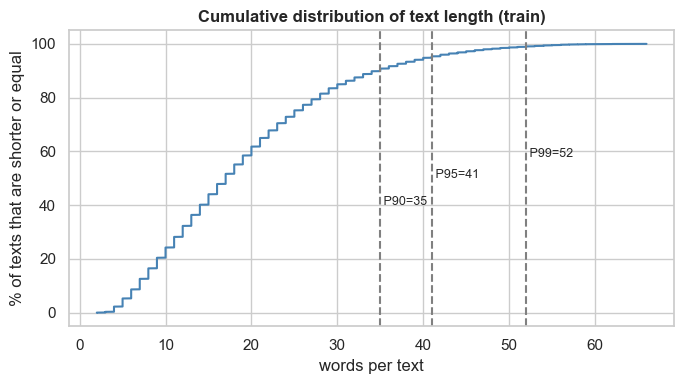

TAKEAWAY -> 90% of texts have ≤ 35 words, 95% ≤ 41, 99% ≤ 52 → a maximum sequence length near 52 keeps ~99% of texts untruncated.


In [8]:
cdf = train.word_count.sort_values().reset_index(drop=True)
p90, p95, p99 = [int(np.ceil(train.word_count.quantile(q))) for q in (0.90, 0.95, 0.99)]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(cdf.values, (np.arange(len(cdf)) + 1) / len(cdf) * 100, color="steelblue")
for q, v in [(90, p90), (95, p95), (99, p99)]:
    ax.axvline(v, ls="--", color="grey"); ax.text(v, 40 + (q - 90) * 2, f" P{q}={v}", fontsize=9)
ax.set_xlabel("words per text"); ax.set_ylabel("% of texts that are shorter or equal"); ax.set_title("Cumulative distribution of text length (train)")
plt.tight_layout(); save_fig(fig, "07_length_ecdf"); plt.show()
FACTS.update(p90=p90, p95=p95, p99=p99)
note("07_length_ecdf", f"90% of texts have ≤ {p90} words, 95% ≤ {p95}, 99% ≤ {p99} → a maximum sequence length near {p99} keeps ~99% of texts untruncated.")

This plot shows the percentage of texts that are shorter than a given length. The 99th percentile is used later as the maximum sequence length for the deep learning models.

## 4. Vocabulary

In [9]:
tok_counts = Counter(w for t in train.text for w in t.split())
total_tokens = sum(tok_counts.values()); vocab_size = len(tok_counts)
hapax = sum(1 for c in tok_counts.values() if c == 1)
ranked = np.array(sorted(tok_counts.values(), reverse=True))
cov = {k: ranked[:k].sum() / total_tokens * 100 for k in (1000, 5000, 10000)}
cov = {k: v for k, v in cov.items()}

vocab_tbl = pd.Series({"total tokens": total_tokens, "unique words (vocabulary)": vocab_size,
                       "words appearing once (hapax)": hapax, "hapax share of vocabulary %": round(hapax / vocab_size * 100, 1),
                       **{f"token coverage of top {k:,} words %": round(v, 2) for k, v in cov.items()}})
FACTS.update(total_tokens=int(total_tokens), vocab_size=int(vocab_size), hapax_pct=float(hapax / vocab_size * 100), coverage={int(k): float(v) for k, v in cov.items()})
vocab_tbl.to_frame("train")

,train
total tokens,305403.00
unique words (vocabulary),15188.00
words appearing once (hapax),7816.00
hapax share of vocabulary %,51.50
"token coverage of top 1,000 words %",85.12
"token coverage of top 5,000 words %",95.81
"token coverage of top 10,000 words %",98.30


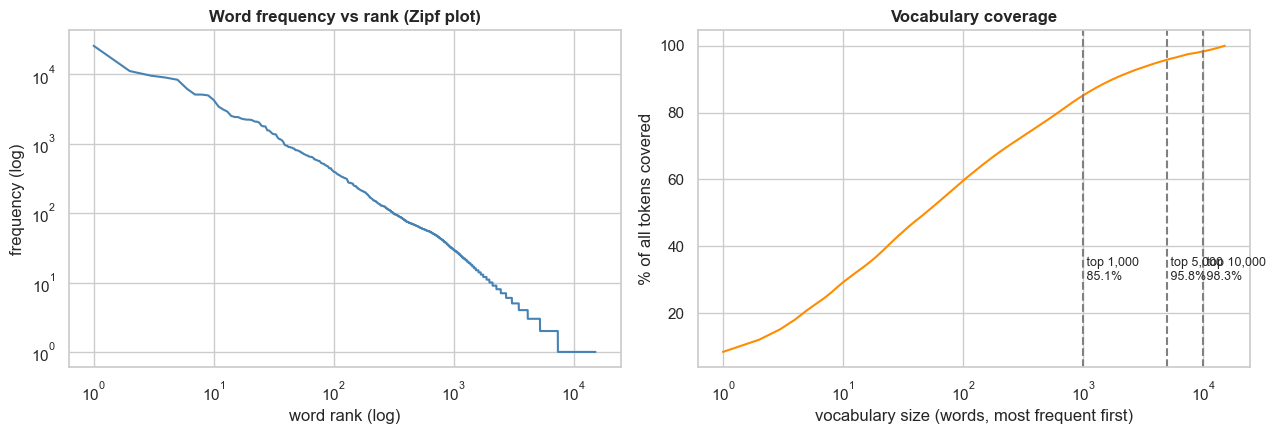

TAKEAWAY -> Vocabulary = 15,188 unique words, 51% of them appear only once; the top 10,000 words already cover 98.30% of all tokens → capping the vocabulary at 5,000–10,000 loses almost nothing.


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].loglog(np.arange(1, len(ranked) + 1), ranked, color="steelblue")
axes[0].set_xlabel("word rank (log)"); axes[0].set_ylabel("frequency (log)"); axes[0].set_title("Word frequency vs rank (Zipf plot)")
x = np.arange(1, len(ranked) + 1); y = np.cumsum(ranked) / total_tokens * 100
axes[1].plot(x, y, color="darkorange")
for k in (1000, 5000, 10000):
    if k < len(x): axes[1].axvline(k, ls="--", color="grey"); axes[1].text(k, 30, f" top {k:,}\n {cov[k]:.1f}%", fontsize=9)
axes[1].set_xlabel("vocabulary size (words, most frequent first)"); axes[1].set_ylabel("% of all tokens covered"); axes[1].set_title("Vocabulary coverage"); axes[1].set_xscale("log")
plt.tight_layout(); save_fig(fig, "08_vocabulary_zipf_coverage"); plt.show()
note("08_vocabulary_zipf_coverage", f"Vocabulary = {vocab_size:,} unique words, {hapax/vocab_size*100:.0f}% of them appear only once; the top 10,000 words already cover {cov[10000]:.2f}% of all tokens "
     f"→ capping the vocabulary at 5,000–10,000 loses almost nothing.")

The left plot shows word frequency against rank (Zipf's law: a few words are very common and many are rare). The right plot shows how much of the text is covered by the top N words, which helps to choose the vocabulary size.

## 5. Most common words per emotion

Stop words and the words feel, feeling, im and ive are removed because they appear in almost every text.

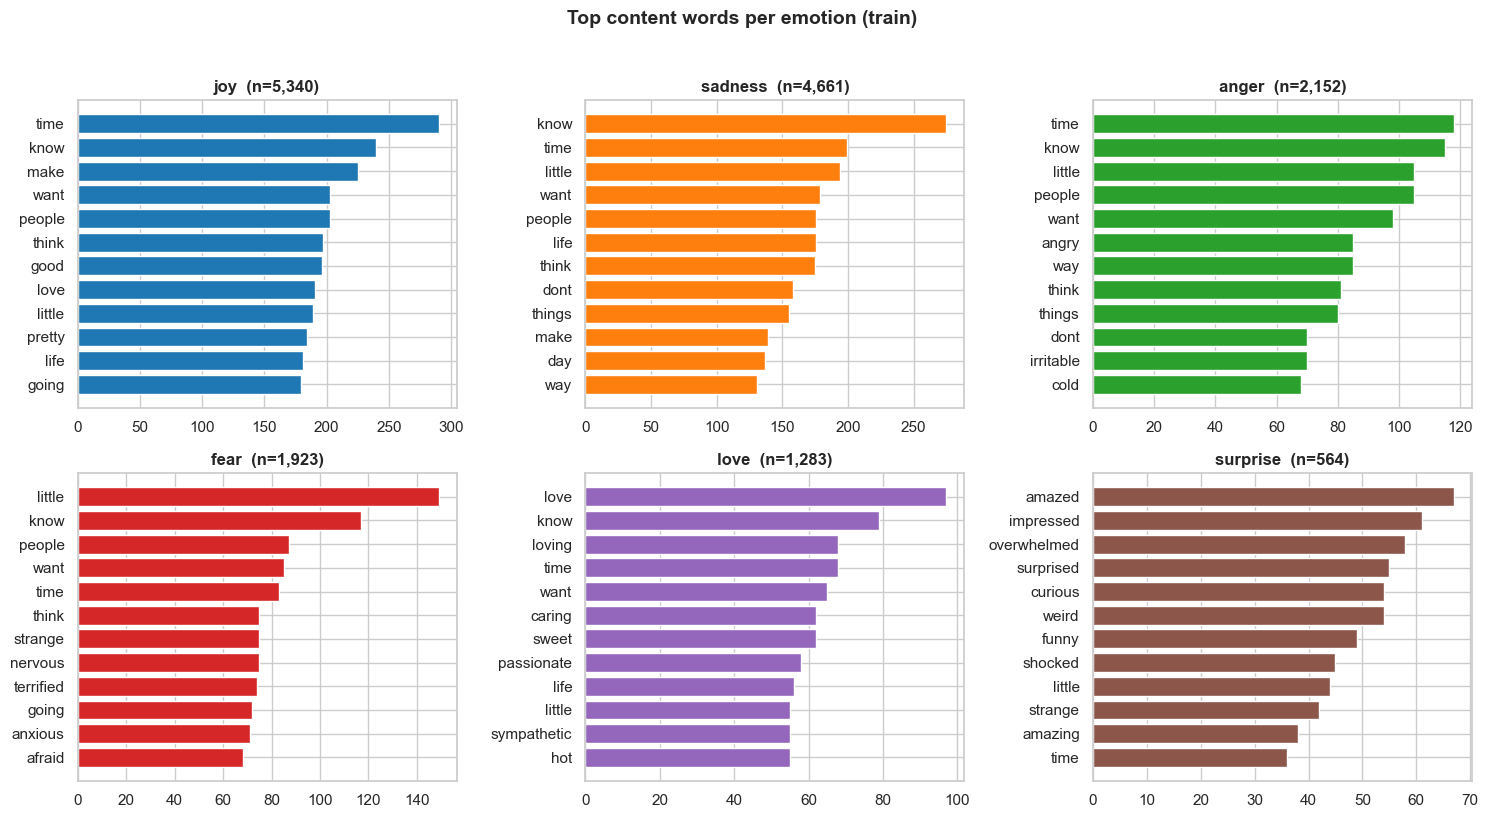

TAKEAWAY -> Top-3 words per class: joy: time, know, make; sadness: know, time, little; anger: time, know, little; fear: little, know, people; love: love, know, loving; surprise: amazed, impressed, overwhelmed.


In [11]:
def top_words(texts, n=12):
    c = Counter(w for t in texts for w in t.split() if w not in STOP and len(w) > 2)
    return c.most_common(n)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, lab in zip(axes.ravel(), order):
    tw = top_words(train.loc[train.label == lab, "text"])
    ax.barh([w for w, _ in tw][::-1], [c for _, c in tw][::-1], color=palette[lab])
    ax.set_title(f"{lab}  (n={int((train.label == lab).sum()):,})")
plt.suptitle("Top content words per emotion (train)", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout(); save_fig(fig, "09_top_words_per_emotion"); plt.show()
top1 = {lab: top_words(train.loc[train.label == lab, "text"], 3) for lab in order}
note("09_top_words_per_emotion", "Top-3 words per class: " + "; ".join(f"{k}: {', '.join(w for w, _ in v)}" for k, v in top1.items()) + ".")

These are the most common words for each emotion.

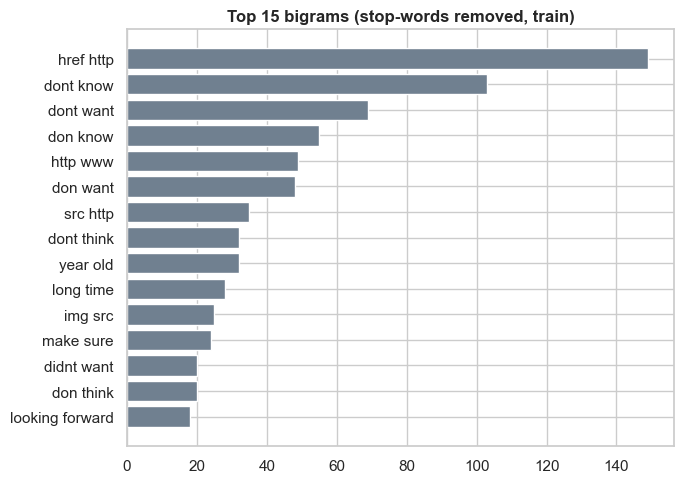

TAKEAWAY -> Most frequent bigram: 'href http' (149 occurrences); phrases carry extra context beyond single words, supporting n-gram TF-IDF features.


In [12]:
cv = CountVectorizer(ngram_range=(2, 2), stop_words=list(STOP), min_df=5)
Xb = cv.fit_transform(train.text)
bi = pd.Series(np.asarray(Xb.sum(0)).ravel(), index=cv.get_feature_names_out()).nlargest(15)
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(bi.index[::-1], bi.values[::-1], color="slategray"); ax.set_title("Top 15 bigrams (stop-words removed, train)")
plt.tight_layout(); save_fig(fig, "10_top_bigrams"); plt.show()
note("10_top_bigrams", f"Most frequent bigram: '{bi.index[0]}' ({bi.iloc[0]} occurrences); phrases carry extra context beyond single words, supporting n-gram TF-IDF features.")

## 6. Most useful words per emotion

I use the chi-square test (one emotion against the rest) to find the words most linked to each emotion.

In [13]:
cv1 = CountVectorizer(binary=True, stop_words=list(STOP), min_df=5)
X1 = cv1.fit_transform(train.text); terms = np.array(cv1.get_feature_names_out())
disc = {}
for lab in order:
    sc, _ = chi2(X1, (train.label == lab).astype(int))
    disc[lab] = terms[np.argsort(sc)[::-1][:10]]
disc_df = pd.DataFrame(disc)
disc_df.index = range(1, 11); disc_df.index.name = "rank"
disc_df

,joy,sadness,anger,fear,love,surprise
rank,,,,,,
1,successful,exhausted,irritable,terrified,sympathetic,amazed
2,satisfied,miserable,offended,shaken,caring,impressed
3,confident,melancholy,greedy,vulnerable,longing,curious
4,glad,punished,resentful,apprehensive,loving,surprised
5,brave,lethargic,fucked,reluctant,nostalgic,shocked
6,divine,discouraged,dissatisfied,uncertain,horny,funny
7,honored,gloomy,dangerous,unsure,loyal,dazed
8,rich,burdened,insulted,pressured,tender,overwhelmed
9,useful,homesick,cranky,nervous,naughty,weird


The table shows the words that best separate each emotion.

## 7. Vocabulary overlap between emotions

Jaccard similarity between the top 300 words of each emotion (1 = same words, 0 = no words in common).

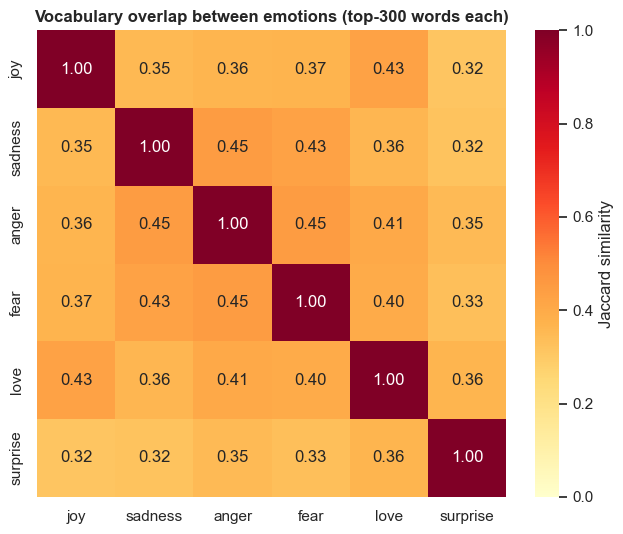

TAKEAWAY -> Most similar vocabularies: 'sadness' & 'anger' (Jaccard 0.45) → expect confusion between them; least similar: 'joy' & 'surprise' (0.32).


In [14]:
topsets = {lab: {w for w, _ in top_words(train.loc[train.label == lab, "text"], 300)} for lab in order}
J = pd.DataFrame([[len(topsets[a] & topsets[b]) / len(topsets[a] | topsets[b]) for b in order] for a in order], index=order, columns=order)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(J, annot=True, fmt=".2f", cmap="YlOrRd", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "Jaccard similarity"})
ax.set_title("Vocabulary overlap between emotions (top-300 words each)")
plt.tight_layout(); save_fig(fig, "11_vocabulary_overlap"); plt.show()
Jm = J.where(~np.eye(len(order), dtype=bool)); a, b = Jm.stack().idxmax(); mx = Jm.stack().max()
c_, d_ = Jm.stack().idxmin()
FACTS.update(most_overlap=[a, b, float(mx)])
note("11_vocabulary_overlap", f"Most similar vocabularies: '{a}' & '{b}' (Jaccard {mx:.2f}) → expect confusion between them; least similar: '{c_}' & '{d_}' ({Jm.stack().min():.2f}).")

Emotions with a high overlap are likely to be confused by the models.

## 8. The word 'feel'

Checking how many texts contain feel, feeling or felt.

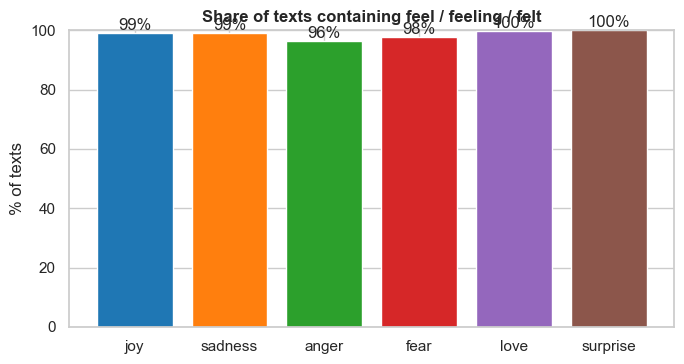

TAKEAWAY -> 99% of train texts contain a form of 'feel', ranging from 96% to 100% across classes.


In [15]:
has_feel = train.text.str.contains(r"\bfe(?:el|els|eling|elings|lt)\b")
share = train.assign(has_feel=has_feel).groupby("label").has_feel.mean().reindex(order) * 100
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(share.index, share.values, color=[palette[c] for c in share.index]); ax.set_ylim(0, 100)
ax.set_ylabel("% of texts"); ax.set_title("Share of texts containing feel / feeling / felt")
for i, v in enumerate(share.values): ax.text(i, v + 1, f"{v:.0f}%", ha="center")
plt.tight_layout(); save_fig(fig, "12_feel_template_share"); plt.show()
FACTS["feel_share_overall"] = float(has_feel.mean() * 100)
note("12_feel_template_share", f"{has_feel.mean()*100:.0f}% of train texts contain a form of 'feel', ranging from {share.min():.0f}% to {share.max():.0f}% across classes.")

## 9. Correlation

Left: correlation between the numeric features. Right: correlation between each feature and each emotion.

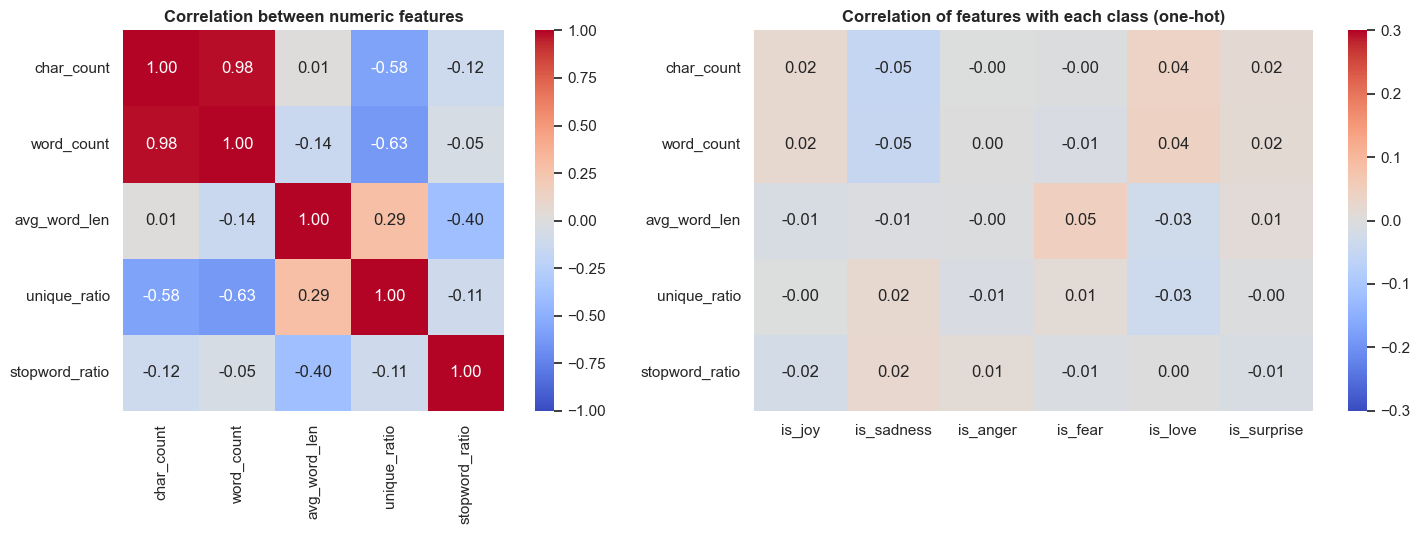

TAKEAWAY -> Most correlated feature pair: char_count & word_count (r = 0.98); strongest feature-label correlation: char_count vs is_sadness (r = -0.05).


In [16]:
onehot = pd.get_dummies(train.label).astype(int)[order].add_prefix("is_")
corr_df = pd.concat([train[NUM], onehot], axis=1)
C = corr_df.corr()

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1, 1.1]})
sns.heatmap(train[NUM].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=axes[0], square=True)
axes[0].set_title("Correlation between numeric features")
sns.heatmap(C.loc[NUM, onehot.columns], annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-0.3, vmax=0.3, ax=axes[1])
axes[1].set_title("Correlation of features with each class (one-hot)")
plt.tight_layout(); save_fig(fig, "13_correlation_heatmaps"); plt.show()

fc = train[NUM].corr().where(~np.eye(len(NUM), dtype=bool)).stack()
f1, f2 = fc.abs().idxmax(); strongest_lab = C.loc[NUM, onehot.columns].abs().stack().idxmax()
FACTS.update(top_feature_corr=[f1, f2, float(fc[(f1, f2)])], top_label_corr=[strongest_lab[0], strongest_lab[1], float(C.loc[strongest_lab])])
note("13_correlation_heatmaps", f"Most correlated feature pair: {f1} & {f2} (r = {fc[(f1, f2)]:.2f}); strongest feature-label correlation: {strongest_lab[0]} vs {strongest_lab[1]} (r = {C.loc[strongest_lab]:.2f}).")

Features that are highly correlated with each other (like characters and words) are redundant. The correlation with the emotions shows how useful each feature is on its own.

## 10. Train, val and test comparison

Checking that the three splits have a similar text length using the KS test.

,KS statistic,p-value
train vs val,0.0140,0.8738
train vs test,0.0178,0.6232


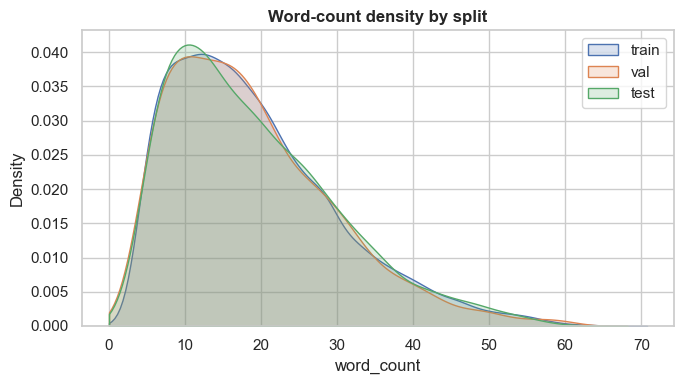

TAKEAWAY -> Length distributions of train/val/test are statistically indistinguishable (KS p-values: train vs val=0.874, train vs test=0.623).


In [17]:
ks = {f"train vs {s}": stats.ks_2samp(train.word_count, data[s].word_count) for s in ("val", "test")}
ks_df = pd.DataFrame({k: {"KS statistic": round(v.statistic, 4), "p-value": round(v.pvalue, 4)} for k, v in ks.items()}).T
display(ks_df)
fig, ax = plt.subplots(figsize=(7, 4))
for s, d in data.items():
    sns.kdeplot(d.word_count, ax=ax, label=s, fill=True, alpha=0.2, common_norm=False, clip=(0, None))
ax.set_title("Word-count density by split"); ax.legend(); plt.tight_layout(); save_fig(fig, "14_split_length_comparison"); plt.show()
ok = all(v.pvalue > 0.05 for v in ks.values())
note("14_split_length_comparison", f"Length distributions of train/val/test {'are statistically indistinguishable' if ok else 'differ significantly'} (KS p-values: " + ", ".join(f"{k}={v.pvalue:.3f}" for k, v in ks.items()) + ").")

## 11. Insights

The findings are collected below and saved in `reports/eda_insights.md`.

In [18]:
F = FACTS
cls = F["class_pct"]; lo, hi = min(cls, key=cls.get), max(cls, key=cls.get)
lines = [
    "## Key findings from EDA",
    "",
    f"1. **Size & quality** – after cleaning: {F['rows']['train']:,} train / {F['rows']['val']:,} val / {F['rows']['test']:,} test texts; no missing values, no duplicates, no train/val/test overlap.",
    f"2. **Class imbalance** – '{hi}' is the largest class ({cls[hi]:.1f}%), '{lo}' the smallest ({cls[lo]:.1f}%); imbalance ratio {F['imbalance_ratio']:.1f}:1. "
    f"The class mix is {'the same' if F['split_chi2_p'] > 0.05 else 'NOT the same'} across splits (chi-square p = {F['split_chi2_p']:.3f}).",
    f"3. **Text length** – mean {F['word_mean']:.1f} words (median {F['word_median']:.0f}, min {F['word_min']}, max {F['word_max']}), skewness {F['word_skew']:.2f}. "
    f"95% of texts have ≤ {F['p95']} words and 99% ≤ {F['p99']}.",
    f"4. **Length vs emotion** – mean words per class: " + ", ".join(f"{k} {v:.1f}" for k, v in F["length_by_class"].items()) + f" (Kruskal-Wallis p = {F['kruskal_p']:.3g}).",
    f"5. **Vocabulary** – {F['vocab_size']:,} unique words in {F['total_tokens']:,} tokens; {F['hapax_pct']:.0f}% of the vocabulary occurs only once; "
    f"the top 10,000 words cover {F['coverage'][10000]:.2f}% of tokens.",
    f"6. **Template words** – {F['feel_share_overall']:.0f}% of texts contain a form of 'feel'" + (", so these words are shared by (almost) every class and carry little class information." if F['feel_share_overall'] > 85 else "."),
    f"7. **Likely confusions** – most overlapping vocabularies: '{F['most_overlap'][0]}' & '{F['most_overlap'][1]}' (Jaccard {F['most_overlap'][2]:.2f}).",
    f"8. **Correlations** – strongest feature pair: {F['top_feature_corr'][0]} & {F['top_feature_corr'][1]} (r = {F['top_feature_corr'][2]:.2f}); "
    f"strongest feature–class correlation r = {F['top_label_corr'][2]:.2f} ({F['top_label_corr'][0]} vs {F['top_label_corr'][1]})" + (" → weak, so the predictive signal is mainly in the words, not in length statistics." if abs(F['top_label_corr'][2]) < 0.3 else " → notable, so numeric features may add value."),
    "",
    "## Implications for modelling (Phase 2)",
    "",
    "- **Imbalance** → use stratified splits (already provided), class weights, and report macro-F1 and per-class recall, not accuracy alone.",
    f"- **Sequence length** → pad/truncate neural-network inputs to about the 99th percentile ({F['p99']} words), not to the maximum.",
    "- **Vocabulary** → cap the vocabulary (5k–10k words) with an out-of-vocabulary token; rare words add noise.",
    "- **Features** → TF-IDF (uni+bigrams) is the natural baseline; numeric length features are redundant with each other and only weakly informative.",
    "- **Scaling** → counts are right-skewed, so apply log1p before standardising; fit all scalers/vectorizers on **train only** to avoid leakage.",
]
insights = "\n".join(lines)
(REP / "eda_insights.md").write_text(insights, encoding="utf-8")
(REP / "eda_facts.json").write_text(json.dumps(FACTS, indent=2, default=float), encoding="utf-8")
with open(REP / "figure_notes_eda.md", "w", encoding="utf-8") as f:
    f.write("# Figure notes — EDA\n\n")
    for k, v in NOTES.items():
        f.write(f"- **images/{k}.png** — {v}\n")
from IPython.display import Markdown
Markdown(insights)

## Key findings from EDA

1. **Size & quality** – after cleaning: 15,923 train / 1,993 val / 2,000 test texts; no missing values, no duplicates, no train/val/test overlap.
2. **Class imbalance** – 'joy' is the largest class (33.5%), 'surprise' the smallest (3.5%); imbalance ratio 9.5:1. The class mix is the same across splits (chi-square p = 0.365).
3. **Text length** – mean 19.2 words (median 17, min 2, max 66), skewness 0.96. 95% of texts have ≤ 41 words and 99% ≤ 52.
4. **Length vs emotion** – mean words per class: joy 19.5, sadness 18.4, anger 19.2, fear 18.9, love 20.8, surprise 20.1 (Kruskal-Wallis p = 3.01e-18).
5. **Vocabulary** – 15,188 unique words in 305,403 tokens; 51% of the vocabulary occurs only once; the top 10,000 words cover 98.30% of tokens.
6. **Template words** – 99% of texts contain a form of 'feel', so these words are shared by (almost) every class and carry little class information.
7. **Likely confusions** – most overlapping vocabularies: 'sadness' & 'anger' (Jaccard 0.45).
8. **Correlations** – strongest feature pair: char_count & word_count (r = 0.98); strongest feature–class correlation r = -0.05 (char_count vs is_sadness) → weak, so the predictive signal is mainly in the words, not in length statistics.

## Implications for modelling (Phase 2)

- **Imbalance** → use stratified splits (already provided), class weights, and report macro-F1 and per-class recall, not accuracy alone.
- **Sequence length** → pad/truncate neural-network inputs to about the 99th percentile (52 words), not to the maximum.
- **Vocabulary** → cap the vocabulary (5k–10k words) with an out-of-vocabulary token; rare words add noise.
- **Features** → TF-IDF (uni+bigrams) is the natural baseline; numeric length features are redundant with each other and only weakly informative.
- **Scaling** → counts are right-skewed, so apply log1p before standardising; fit all scalers/vectorizers on **train only** to avoid leakage.